In [1]:
import os, re
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

from google.colab import drive
drive.mount('/content/drive')

data = "/content/drive/MyDrive/DS340project/PMEmo2019/"
lyrics_folder = "/content/drive/My Drive/DS340project/PMEmo2019/lyrics/"

metadata = pd.read_csv("/content/drive/MyDrive/DS340project/PMEmo2019/metadata.csv")
print(len(metadata), "songs |", len(os.listdir(lyrics_folder)), "lyric files")

Mounted at /content/drive
794 songs | 629 lyric files


In [2]:
def get_lyrics(music_id):
    path = lyrics_folder + str(music_id) + ".lrc"
    if not os.path.exists(path):
        return ""
    text = open(path, encoding="utf-8", errors="ignore").read()
    text = re.sub(r"\[.*?\]", " ", text)   #remove timestamps
    text = re.sub(r"\s+", " ", text)        #collapse spaces/newlines
    return text.strip()

metadata["lyrics"] = metadata["musicId"].apply(get_lyrics)
lyrics = metadata[metadata["lyrics"].str.split().str.len() >= 20]
lyrics.head()

,musicId,fileName,title,artist,album,duration,chorus_start_time,chorus_end_time,lyrics
0,1,1.mp3,Good Drank,2 Chainz,"Def Jam Presents: Direct Deposit, Vol. 2",32.10,02:35,03:05,"Uhh, (yeah) alright I did it, hahah, yeah Used..."
2,5,5.mp3,No Heart,21 Savage,Savage Mode,84.23,00:41,02:03,"{Hook} Young Savage, why you trappin' so hard?..."
3,6,6.mp3,Red Opps,21 Savage,Red Opps,29.53,02:16,02:44,"Yeah, Yeah, Yeah I pull up roll the window dow..."
6,9,9.mp3,Timeless,A Boogie Wit Da Hoodie,TBA,23.09,01:57,02:18,"Bitch, I'm really timeless I cannot waste no t..."
7,10,10.mp3,Drowning,A Boogie Wit Da Hoodie,Drowning,32.10,02:43,03:13,I'm drownin' I'm drownin' I'm drownin' I'm dro...


In [3]:
model = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = model.encode(lyrics["lyrics"].tolist(), show_progress_bar=True)
embeddings.shape

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

(625, 384)

In [4]:
np.save("/content/drive/My Drive/DS340project/lyrics_embeddings.npy", embeddings)
lyrics[["musicId", "lyrics"]].to_csv("/content/drive/My Drive/DS340project/lyrics_clean.csv", index=False)

### embedding

In [5]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

project = "/content/drive/MyDrive/DS340project/"

X   = np.load(project + "X_lyrics_filtered.npy")
y   = np.load(project + "y_lyrics_filtered.npy").astype(int)
ids = np.load(project + "music_ids_filtered.npy").astype(int)
train_ids = np.load(project + "train_music_ids.npy").astype(int)
test_ids  = np.load(project + "test_music_ids.npy").astype(int)

#two binary labels: 0 sad, 1 calm, 2 tense, 3 happy

#calm, happy = 1
y_valence = y % 2

#tense, happy = 1
y_arousal = y // 2

is_train = np.isin(ids, train_ids)
is_test  = np.isin(ids, test_ids)
X_train, X_test = X[is_train], X[is_test]
print(X.shape, "|", is_train.sum(), "train |", is_test.sum(), "test")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(605, 384) | 484 train | 121 test


valence: acc=0.769  macro-F1=0.731


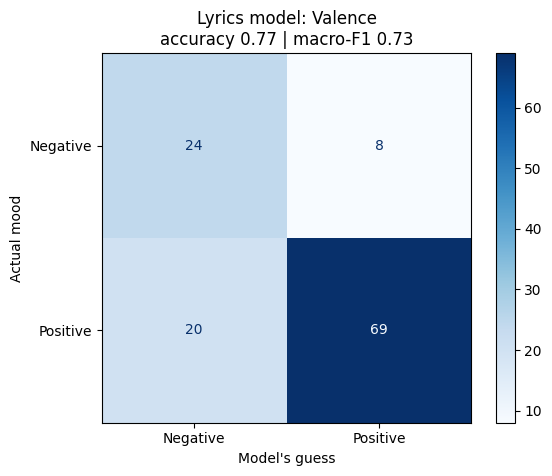

arousal: acc=0.620  macro-F1=0.565


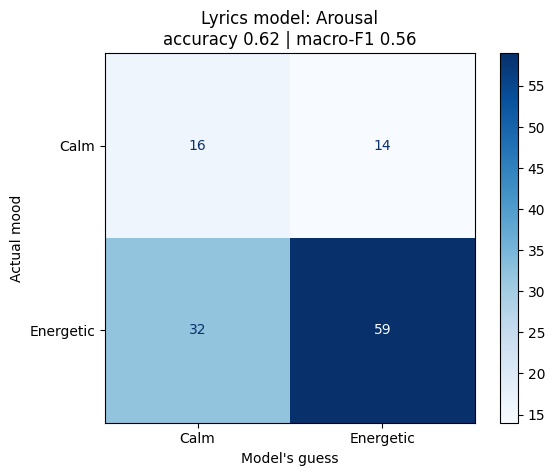

In [6]:
import matplotlib.pyplot as plt

labels = {"valence": y_valence, "arousal": y_arousal}
names  = {"valence": ["Negative", "Positive"],
          "arousal": ["Calm", "Energetic"]}
models = {}

for name, yy in labels.items():
    clf = LogisticRegressionCV(Cs=10, cv=5, class_weight="balanced",
                               scoring="f1_macro", max_iter=2000)
    clf.fit(X_train, yy[is_train])
    models[name] = clf
    pred = clf.predict(X_test)

    acc = accuracy_score(yy[is_test], pred)
    f1  = f1_score(yy[is_test], pred, average="macro")
    print(f"{name}: acc={acc:.3f}  macro-F1={f1:.3f}")

    disp = ConfusionMatrixDisplay.from_predictions(
        yy[is_test], pred, display_labels=names[name], cmap="Blues")
    disp.ax_.set_title(f"Lyrics model: {name.capitalize()}\n"
                       f"accuracy {acc:.2f} | macro-F1 {f1:.2f}")
    disp.ax_.set_xlabel("Model's guess")
    disp.ax_.set_ylabel("Actual mood")
    plt.show()

Quadrant acc=0.562  macro-F1=0.302


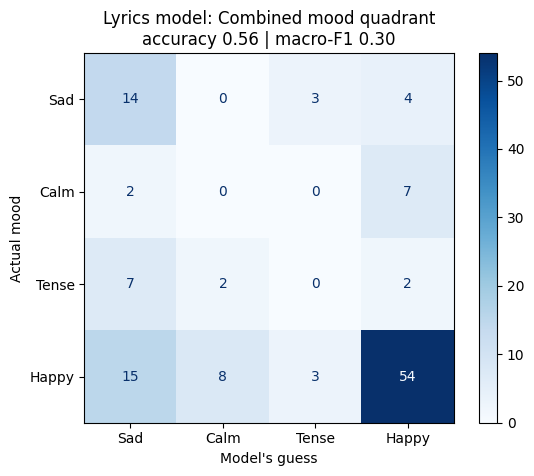

In [10]:
pred_mood = 2 * models["arousal"].predict(X_test) + models["valence"].predict(X_test)
acc = accuracy_score(y[is_test], pred_mood)
f1  = f1_score(y[is_test], pred_mood, average="macro")
print(f"Quadrant acc={acc:.3f}  macro-F1={f1:.3f}")

disp = ConfusionMatrixDisplay.from_predictions(
    y[is_test], pred_mood, display_labels=["Sad", "Calm", "Tense", "Happy"], cmap="Blues")
disp.ax_.set_title(f"Lyrics model: Combined mood quadrant\n"
                   f"accuracy {acc:.2f} | macro-F1 {f1:.2f}")
disp.ax_.set_xlabel("Model's guess")
disp.ax_.set_ylabel("Actual mood")
plt.show()

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
out_train = pd.DataFrame({"musicId": ids[is_train]})
out_test  = pd.DataFrame({"musicId": ids[is_test]})
for name, yy in labels.items():
    out_train[f"lyr_{name}_prob"] = cross_val_predict(models[name], X_train, yy[is_train],
                                                      cv=skf, method="predict_proba")[:, 1]
    out_test[f"lyr_{name}_prob"] = models[name].predict_proba(X_test)[:, 1]

out_train.to_csv(project + "lyrics_oof_train.csv", index=False)
out_test.to_csv(project + "lyrics_probs_test.csv", index=False)